# I-N110 → I-N120 멀티모달 nnU-Net 연속 실험

팀원의 I-N00/I-N10과 기존 I-N20/I-N30/I-N40 결과는 수정하지 않는다. 이 노트북은 **I-N110 Dual-Stem** 완료 후 **I-N120 Dual-Encoder + multi-scale gated fusion**을 자동으로 이어서 실행한다.

공통 조건: DWI+ADC, fold 0, 300 epochs, early stopping 없음, epoch 150부터 10 epoch 간격 full-volume validation, Top-3 anchor의 ±5 epoch 재평가, best 확률맵 저장, threshold sweep.

In [6]:
from pathlib import Path
import json, os, signal, subprocess, time
import pandas as pd
from IPython.display import display

REPO = Path("/home/stu03/workspace/model")
PYTHON = REPO / ".venv/bin/python"
assert PYTHON.is_file(), PYTHON

EXPERIMENTS = ["I-N110", "I-N120"]
CONFIGS = {x: REPO / f"configs/experiments/ischemia/{x}.yaml" for x in EXPERIMENTS}
CONFIGS

{'I-N110': PosixPath('/home/stu03/workspace/model/configs/experiments/ischemia/I-N110.yaml'),
 'I-N120': PosixPath('/home/stu03/workspace/model/configs/experiments/ischemia/I-N120.yaml')}

## 모델 차이

- **I-N110**: DWI/ADC별 초기 stem을 학습한 뒤 feature를 합쳐 shared residual encoder/decoder로 전달한다.
- **I-N120**: DWI/ADC 전체 encoder를 독립 학습하고 각 scale에서 learnable gate로 feature를 합친 뒤 shared decoder로 전달한다.
- 비교 기준과 split은 기존 I-N20~I-N40과 동일하다.

In [2]:
# 실제 학습 없이 모든 경로와 명령 확인
subprocess.run([str(PYTHON), str(REPO / "scripts/ischemia/training/run_i_n_multimodal_sequence.py"), "--dry-run"], cwd=REPO, check=True)

[START] I-N110
{
  "experiment": "I-N110",
  "mode": "new",
  "output_folder": "/home/stu03/workspace/model/runs/I-nnunet/Dataset502_ISLES2022/nnUNetTrainerIschemiaMultimodal__IschemiaPlansDualStemV1__3d_fullres/fold_0",
  "prepare": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/preprocessing/prepare_i_n20_plans.py",
    "--config",
    "/home/stu03/workspace/model/configs/experiments/ischemia/I-N110.yaml",
    "--data-root",
    "/home/stu03/workspace/datasets/ischemic/nnunet"
  ],
  "train": [
    "/home/stu03/workspace/model/.venv/bin/nnUNetv2_train",
    "502",
    "3d_fullres",
    "0",
    "-tr",
    "nnUNetTrainerIschemiaMultimodal",
    "-p",
    "IschemiaPlansDualStemV1",
    "-device",
    "cuda"
  ],
  "post_training_selection": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/ischemia/validation/evaluate_i_n_multimodal_neighborhood.py",
    "--config",
    "/home/stu03/wo

CompletedProcess(args=['/home/stu03/workspace/model/.venv/bin/python', '/home/stu03/workspace/model/scripts/ischemia/training/run_i_n_multimodal_sequence.py', '--dry-run'], returncode=0)

## 연속 학습 시작/재개

아래 셀을 한 번 실행하면 background에서 I-N110을 수행하고 정상 완료된 경우에만 I-N120으로 넘어간다. checkpoint가 있으면 자동 재개하며, 이미 최종 평가와 확률맵까지 끝난 실험은 건너뛴다.

In [7]:
LOG = REPO / "runs/I-nnunet/I-N110_N120_sequence.log"
PID_FILE = REPO / "runs/I-nnunet/I-N110_N120_sequence.pid"
PID_FILE.parent.mkdir(parents=True, exist_ok=True)

def pid_is_running(pid: int) -> bool:
    try:
        os.kill(pid, 0)
    except ProcessLookupError:
        return False
    stat = Path(f"/proc/{pid}/stat")
    return not stat.is_file() or stat.read_text().split()[2] != "Z"  # zombie PID 제외

if PID_FILE.is_file():
    old_pid = int(PID_FILE.read_text().strip())
    if pid_is_running(old_pid):
        raise RuntimeError(f"이미 실행 중입니다: PID={old_pid}")
    PID_FILE.unlink()  # 종료된 실행의 stale PID 제거

# 새 실행이므로 이전 traceback을 누적하지 않는다.
handle = LOG.open("w", buffering=1)
proc = subprocess.Popen(
    [str(PYTHON), str(REPO / "scripts/ischemia/training/run_i_n_multimodal_sequence.py")],
    cwd=REPO, stdout=handle, stderr=subprocess.STDOUT, start_new_session=True,
)
PID_FILE.write_text(str(proc.pid))
print(f"started PID={proc.pid} | log={LOG}")


started PID=2492242 | log=/home/stu03/workspace/model/runs/I-nnunet/I-N110_N120_sequence.log


## 실시간 진행률

In [9]:
import yaml
from IPython.display import clear_output

def process_alive(pid_file):
    if not pid_file.is_file(): return False
    try:
        os.kill(int(pid_file.read_text()), 0); return True
    except (ProcessLookupError, ValueError): return False

try:
    while True:
        rows=[]
        for eid in EXPERIMENTS:
            c=yaml.safe_load(CONFIGS[eid].read_text()); e,p=c["experiment"],c["plans"]
            fold=Path(c["paths"]["results_root"])/f"Dataset{int(e['dataset_id']):03d}_{e['dataset_name']}"/f"nnUNetTrainerIschemiaMultimodal__{p['output_identifier']}__{e['configuration']}"/f"fold_{e['fold']}"
            progress=fold/"progress.json"; row={"experiment":eid,"result":str(fold),"status":"waiting"}
            if progress.is_file(): row.update(json.loads(progress.read_text()))
            row["probability_maps"]=len(list((fold/"best_probability_validation").glob("*.npz")))
            rows.append(row)
        clear_output(wait=True)
        print(time.strftime("Updated: %Y-%m-%d %H:%M:%S"))
        display(pd.DataFrame(rows).reindex(columns=["experiment","status","current_epoch","total_epochs","progress_percent","eta_seconds","best_full_macro_dice","best_full_macro_epoch","probability_maps","result"]))
        if LOG.is_file(): print("\n--- latest log ---\n"+"".join(LOG.read_text(errors="replace").splitlines(True)[-20:]))
        if not process_alive(PID_FILE):
            print("\n연속 실행 프로세스가 종료되었습니다. 마지막 상태입니다."); break
        time.sleep(10)
except KeyboardInterrupt:
    print("모니터만 중단했습니다. background 학습은 계속됩니다.")

Updated: 2026-09-18 00:44:18


,experiment,status,current_epoch,total_epochs,progress_percent,eta_seconds,best_full_macro_dice,best_full_macro_epoch,probability_maps,result
0,I-N110,completed,300,300,100.0,0.0,0.802805,170,38,/home/stu03/workspace/model/runs/I-nnunet/Data...
1,I-N120,completed,300,300,100.0,0.0,0.813491,160,38,/home/stu03/workspace/model/runs/I-nnunet/Data...



--- latest log ---
[SKIP] I-N110: final selection/probability maps already exist
[SKIP] I-N120: final selection/probability maps already exist
[
  {
    "experiment": "I-N110",
    "status": "skipped_completed"
  },
  {
    "experiment": "I-N120",
    "status": "skipped_completed"
  }
]

모니터만 중단했습니다. background 학습은 계속됩니다.


## 중단

필요할 때만 실행한다. sequence와 현재 child 학습 프로세스 그룹에 SIGTERM을 보내며 checkpoint는 보존된다.

In [ ]:
pid=int(PID_FILE.read_text()); os.killpg(pid, signal.SIGTERM); print(f"stop requested: {pid}")

## 완료 결과 및 상세 평가

학습이 끝난 뒤 실행한다. I-N110/I-N120의 동일 validation set 결과를 단일 표와 크기별·threshold·확률 품질·worst case로 확인한다.


### I-N110 — final evaluation

,metric,n_valid,mean,std,median,q1,q3
4,dice,38,0.811559,0.139803,0.853322,0.781568,0.884747
5,iou,38,0.701595,0.165840,0.744183,0.641458,0.793316
6,precision,38,0.911775,0.083284,0.955060,0.832064,0.975835
7,recall_sensitivity,38,0.768572,0.198062,0.816294,0.653033,0.914119
13,mcc,38,0.824493,0.117351,0.857347,0.799938,0.889091
14,hd95_mm,38,7.799648,10.233843,3.796875,2.000000,6.908327
16,assd_mm,38,1.444633,3.030118,0.687663,0.386505,1.023694
20,abs_volume_error_ml,38,3.145203,5.722051,0.824000,0.182235,3.658000
27,false_positive_lesions,38,0.631579,0.942138,0.000000,0.000000,1.000000
28,lesion_precision,38,0.892812,0.166911,1.000000,0.825175,1.000000



개별 병변 크기별 성능 (I-N40과 동일 기준)


,size_group,gt_lesions,detected_lesions,detection_rate,mean_lesion_dice,median_lesion_dice,median_volume_ml,detected/total
0,<0.01 mL,18,4,0.222222,0.138942,0.000000,0.007151,4/18
1,0.01–0.05 mL,76,24,0.315789,0.218758,0.000000,0.030996,24/76
2,0.05–0.1 mL,30,17,0.566667,0.358073,0.041493,0.066661,17/30
3,0.1–0.5 mL,72,64,0.888889,0.603295,0.745370,0.200737,64/72
4,≥0.5 mL,55,52,0.945455,0.705837,0.835200,2.568000,52/55



Threshold 비교 (추천 / Dice 최고 / 기본 0.5)


,threshold,macro_dice,voxel_recall,voxel_precision,lesion_recall,lesion_precision,lesion_f1,lesion_f2,fp_per_scan
0,0.10,0.817924,0.796420,0.884988,0.677291,0.861905,0.758526,0.707604,0.763158
1,0.15,0.816693,0.790711,0.890085,0.677291,0.864734,0.759620,0.707984,0.736842
8,0.50,0.811559,0.768572,0.911775,0.641434,0.878788,0.741582,0.678062,0.631579



확률 품질 (voxel-weighted; PR-AUC는 100-bin 근사)


,voxel_count,positive_voxel_count,brier_score,ece_100_bins,pr_auc_100_bin_approx,note
0,32431801,71777,0.000583,0.000555,0.80909,Voxel-weighted; PR-AUC is a histogram approxim...



Worst 10 cases


,case_id,dice,recall_sensitivity,precision,lesion_recall,false_positive_lesions,hd95_mm,nsd_2mm,gt_volume_ml,pred_volume_ml,abs_volume_error_ml
10,sub-strokecase0068,0.242884,0.138829,0.969697,0.666667,0,38.178047,0.345309,3.688,0.528,3.160
18,sub-strokecase0098,0.510121,0.364162,0.851351,0.600000,2,27.025525,0.708502,1.384,0.592,0.792
11,sub-strokecase0076,0.534749,0.365918,0.992832,0.535714,1,22.360680,0.736178,6.056,2.232,3.824
15,sub-strokecase0092,0.647175,0.496123,0.930470,0.750000,0,14.142136,0.589730,66.032,35.208,30.824
36,sub-strokecase0234,0.681818,0.517241,1.000000,0.666667,0,32.972595,0.863636,0.232,0.120,0.112
6,sub-strokecase0040,0.705882,0.556142,0.965969,0.666667,2,6.000000,0.839532,10.616,6.112,4.504
8,sub-strokecase0050,0.728387,0.586494,0.960851,0.545455,4,7.211103,0.824980,15.400,9.400,6.000
2,sub-strokecase0018,0.757009,0.609023,1.000000,1.000000,0,2.828427,0.940594,1.064,0.648,0.416
19,sub-strokecase0118,0.777861,0.651629,0.964750,0.833333,2,4.472136,0.907591,6.384,4.312,2.072
20,sub-strokecase0138,0.780488,0.640000,1.000000,1.000000,0,2.000000,1.000000,0.200,0.128,0.072


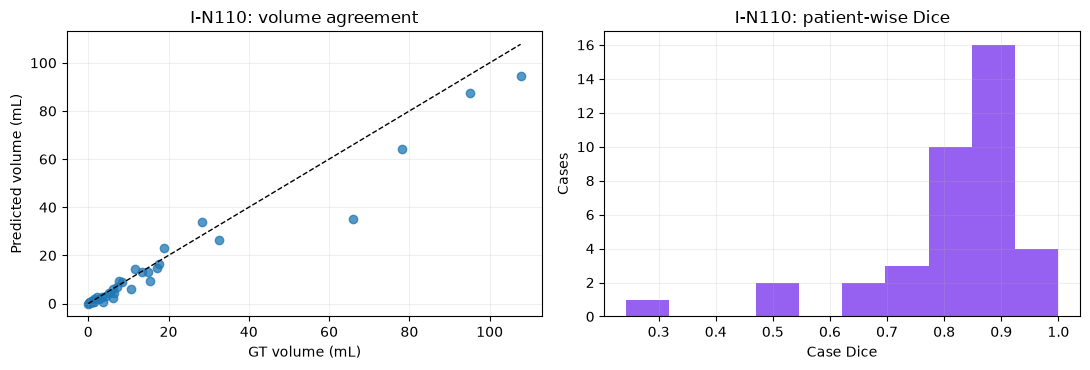

### I-N120 — final evaluation

,metric,n_valid,mean,std,median,q1,q3
4,dice,38,0.812360,0.133764,0.855538,0.772438,0.891192
5,iou,38,0.701382,0.161136,0.747549,0.629278,0.803749
6,precision,38,0.881347,0.099240,0.910293,0.818367,0.957234
7,recall_sensitivity,38,0.791042,0.192963,0.839757,0.677937,0.932472
13,mcc,38,0.823183,0.115748,0.859174,0.776682,0.892742
14,hd95_mm,38,7.129627,10.077079,3.034667,2.000000,6.000000
16,assd_mm,38,1.399508,3.006736,0.638877,0.353413,1.059947
20,abs_volume_error_ml,38,2.878675,5.003521,0.866447,0.218000,3.031221
27,false_positive_lesions,38,0.605263,1.001066,0.000000,0.000000,1.000000
28,lesion_precision,38,0.905404,0.151164,1.000000,0.836538,1.000000



개별 병변 크기별 성능 (I-N40과 동일 기준)


,size_group,gt_lesions,detected_lesions,detection_rate,mean_lesion_dice,median_lesion_dice,median_volume_ml,detected/total
0,<0.01 mL,18,3,0.166667,0.114815,0.000000,0.007151,3/18
1,0.01–0.05 mL,76,31,0.407895,0.266895,0.000000,0.030996,31/76
2,0.05–0.1 mL,30,19,0.633333,0.452894,0.594118,0.066661,19/30
3,0.1–0.5 mL,72,64,0.888889,0.616905,0.729532,0.200737,64/72
4,≥0.5 mL,55,52,0.945455,0.695532,0.811511,2.568000,52/55



Threshold 비교 (추천 / Dice 최고 / 기본 0.5)


,threshold,macro_dice,voxel_recall,voxel_precision,lesion_recall,lesion_precision,lesion_f1,lesion_f2,fp_per_scan
1,0.15,0.815579,0.811828,0.862127,0.693227,0.860577,0.767890,0.721279,0.763158
8,0.50,0.812362,0.791044,0.881347,0.673307,0.885572,0.764988,0.707209,0.605263



확률 품질 (voxel-weighted; PR-AUC는 100-bin 근사)


,voxel_count,positive_voxel_count,brier_score,ece_100_bins,pr_auc_100_bin_approx,note
0,32431801,71777,0.000565,0.000534,0.821446,Voxel-weighted; PR-AUC is a histogram approxim...



Worst 10 cases


,case_id,dice,recall_sensitivity,precision,lesion_recall,false_positive_lesions,hd95_mm,nsd_2mm,gt_volume_ml,pred_volume_ml,abs_volume_error_ml
10,sub-strokecase0068,0.240602,0.138829,0.901408,0.666667,0,38.178047,0.341897,3.688,0.568,3.120
18,sub-strokecase0098,0.594982,0.479769,0.783019,0.733333,2,16.217186,0.799283,1.384,0.848,0.536
11,sub-strokecase0076,0.607237,0.454425,0.914894,0.714286,5,23.056291,0.772163,6.056,3.008,3.048
36,sub-strokecase0234,0.622222,0.482759,0.875000,0.666667,0,34.571560,0.844444,0.232,0.128,0.104
8,sub-strokecase0050,0.709891,0.557403,0.977231,0.636364,1,6.000000,0.825726,15.400,8.784,6.616
15,sub-strokecase0092,0.717824,0.591592,0.912540,0.750000,0,10.198039,0.682287,66.032,42.808,23.224
20,sub-strokecase0138,0.717949,0.560000,1.000000,1.000000,0,2.000000,1.000000,0.200,0.112,0.088
6,sub-strokecase0040,0.739191,0.599096,0.964806,0.666667,2,6.000000,0.865734,10.616,6.592,4.024
16,sub-strokecase0093,0.745455,0.976190,0.602941,1.000000,0,2.000000,0.981818,0.336,0.544,0.208
17,sub-strokecase0097,0.769312,0.804396,0.737160,0.777778,1,10.198039,0.934122,7.280,7.944,0.664


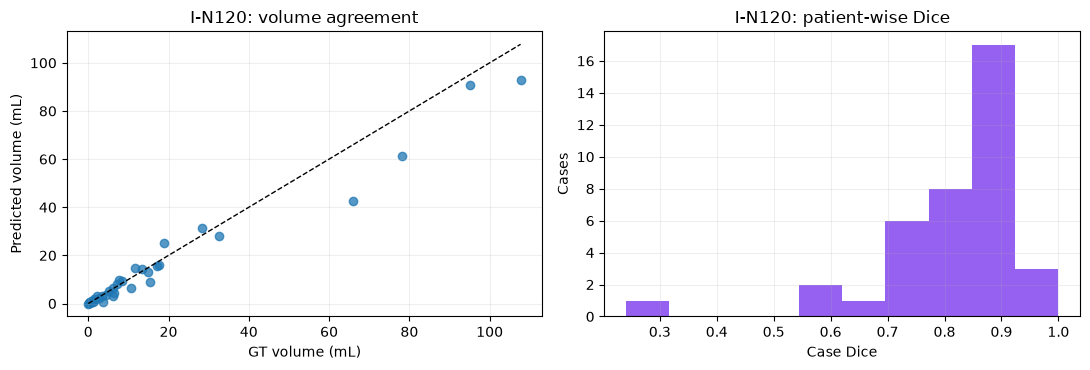

## I-N110 vs I-N120


,experiment,status,selected_epoch,selection_macro_dice,selection_lesion_recall,hard_mask_dice,lesion_recall,lesion_precision,fp_per_scan,complete_miss_cases,recommended_threshold,recommended_lesion_f2,pr_auc_approx,brier_score,ece_100_bins
0,I-N110,completed,169,0.806466,0.641434,0.811559,0.641434,0.878788,0.631579,0,0.15,0.707984,0.809090,0.000583,0.000555
1,I-N120,completed,190,0.807289,0.673307,0.812360,0.673307,0.885572,0.605263,0,0.15,0.721279,0.821446,0.000565,0.000534


In [13]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import yaml

CORE = [
    "dice", "iou", "precision", "recall_sensitivity", "mcc",
    "hd95_mm", "assd_mm", "nsd_2mm", "abs_volume_error_ml",
    "lesion_precision", "lesion_recall", "lesion_f1",
    "false_positive_lesions",
]
summary_rows = []

for eid in EXPERIMENTS:
    config = yaml.safe_load(CONFIGS[eid].read_text())
    exp, plans = config["experiment"], config["plans"]
    fold = (
        Path(config["paths"]["results_root"])
        / f"Dataset{int(exp['dataset_id']):03d}_{exp['dataset_name']}"
        / f"nnUNetTrainerIschemiaMultimodal__{plans['output_identifier']}__{exp['configuration']}"
        / f"fold_{exp['fold']}"
    )
    final_dir = fold / "final_metrics"
    selection_path = fold / "final_selection.json"
    if not selection_path.is_file() or not (final_dir / "per_case.csv").is_file():
        summary_rows.append({"experiment": eid, "status": "not completed"})
        continue

    selection = json.loads(selection_path.read_text())["selected"]
    summary = json.loads((final_dir / "summary.json").read_text())
    threshold_report = json.loads((final_dir / "threshold_summary.json").read_text()) if (final_dir / "threshold_summary.json").is_file() else {}
    recommended = threshold_report.get("recommended_lesion_f2", {})
    probability_quality = threshold_report.get("probability_quality", {})
    summary_rows.append({
        "experiment": eid,
        "status": "completed",
        "selected_epoch": selection.get("epoch"),
        "selection_macro_dice": selection.get("macro_dice_positive"),
        "selection_lesion_recall": selection.get("lesion_detection_rate"),
        "hard_mask_dice": summary["macro"]["dice"]["mean"],
        "lesion_recall": summary.get("micro_lesion_recall"),
        "lesion_precision": summary.get("micro_lesion_precision"),
        "fp_per_scan": summary.get("fp_per_scan"),
        "complete_miss_cases": summary.get("complete_miss_cases"),
        "recommended_threshold": recommended.get("threshold"),
        "recommended_lesion_f2": recommended.get("lesion_f2"),
        "pr_auc_approx": probability_quality.get("pr_auc_100_bin_approx"),
        "brier_score": probability_quality.get("brier_score"),
        "ece_100_bins": probability_quality.get("ece_100_bins"),
    })

    display(Markdown(f"### {eid} — final evaluation"))
    detail_path = final_dir / "summary_metrics.csv"
    if detail_path.is_file():
        detail = pd.read_csv(detail_path)
        display(detail[detail["metric"].isin(CORE)][["metric", "n_valid", "mean", "std", "median", "q1", "q3"]])
    else:
        print("상세 요약 파일이 아직 없어 summary.json의 기존 요약을 표시합니다.")
        display(pd.DataFrame(summary["macro"]).T.loc[lambda x: x.index.intersection(CORE)])

    size_path = final_dir / "lesion_size_summary.csv"
    if size_path.is_file():
        print("\n개별 병변 크기별 성능 (I-N40과 동일 기준)")
        display(pd.read_csv(size_path))
    else:
        print("\n개별 병변 크기별 표는 아직 생성되지 않았습니다.")

    sweep_path = final_dir / "threshold_sweep.csv"
    if sweep_path.is_file():
        print("\nThreshold 비교 (추천 / Dice 최고 / 기본 0.5)")
        sweep = pd.read_csv(sweep_path)
        selected_thresholds = sorted({recommended.get("threshold", 0.5), 0.5, float(sweep.loc[sweep["macro_dice"].idxmax(), "threshold"])})
        columns = [x for x in ["threshold", "macro_dice", "voxel_recall", "voxel_precision", "lesion_recall", "lesion_precision", "lesion_f1", "lesion_f2", "fp_per_scan"] if x in sweep]
        display(sweep[sweep["threshold"].isin(selected_thresholds)][columns])
    else:
        print("\nThreshold sweep 파일이 아직 생성되지 않았습니다.")
    if probability_quality:
        print("\n확률 품질 (voxel-weighted; PR-AUC는 100-bin 근사)")
        display(pd.DataFrame([probability_quality]))

    cases = pd.read_csv(final_dir / "per_case.csv")
    worst = cases.sort_values(
        ["dice", "lesion_recall", "abs_volume_error_ml"],
        ascending=[True, True, False],
    ).head(10)
    print("\nWorst 10 cases")
    display(worst[[
        "case_id", "dice", "recall_sensitivity", "precision", "lesion_recall",
        "false_positive_lesions", "hd95_mm", "nsd_2mm", "gt_volume_ml",
        "pred_volume_ml", "abs_volume_error_ml",
    ]])

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].scatter(cases["gt_volume_ml"], cases["pred_volume_ml"], alpha=.75)
    limit = max(cases["gt_volume_ml"].max(), cases["pred_volume_ml"].max(), 1)
    axes[0].plot([0, limit], [0, limit], "k--", linewidth=1)
    axes[0].set(xlabel="GT volume (mL)", ylabel="Predicted volume (mL)", title=f"{eid}: volume agreement")
    axes[1].hist(cases["dice"], bins=10, color="#7c3aed", alpha=.8)
    axes[1].set(xlabel="Case Dice", ylabel="Cases", title=f"{eid}: patient-wise Dice")
    for axis in axes: axis.grid(alpha=.2)
    plt.tight_layout(); plt.show()

print("## I-N110 vs I-N120")
display(pd.DataFrame(summary_rows))



